# Teaching a cheap AI model to read climate policy like an expert

Governments write their climate commitments into laws, policies and submissions to the UNFCCC (United Nations
Framework Convention on Climate Change), such as each country's NDC (Nationally Determined Contribution) under the
Paris Agreement. Analysts who track these commitments have to find the real **targets** among pages of background,
history, projects and aspirations.

**Task.** For a passage from a national climate document, decide which kinds of target it contains:

| Label | Meaning |
|---|---|
| Net zero | a commitment to balance greenhouse-gas emissions with removals by a date |
| Reduction | a quantified cut in greenhouse-gas emissions, with a deadline |
| Other | any other quantified, dated goal (renewable energy, hydrogen, forests, electric vehicles...) |

A passage can have several labels or none.

**Data.** 2,610 passages from 189 countries and the EU, labelled by three domain experts at Climate Policy Radar
(Juhasz et al. 2024, arXiv:2404.02822; Hugging Face `ClimatePolicyRadar/national-climate-targets`, CC-BY-4.0).

**Question.** Can GEPA, an automatic prompt optimiser, teach a cheap model (Claude Haiku) the experts' judgment,
starting from a prompt that *already contains the experts' written definition*? Compared with a bigger model
(Claude Sonnet) and with classical machine learning tuned by grid search.

Evaluation: a held-out set of 300 passages from unseen countries (with all 32 Indian passages), then 5-fold
cross-validation by country for error bars. All language-model calls go through Claude Code (`claude -p`) and are
cached in `cache/dspy`, so re-running this notebook reproduces every number below exactly.

In [1]:
%matplotlib inline
import json, math, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, dspy
from gepa_targets import targets, targets_ml
from gepa_targets.lm import claude_lm, usage

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)

STUDENT, TEACHER = "haiku", "sonnet"
RUN_GEPA = False   # True re-runs GEPA (about 6 minutes); False loads the saved run from results/
THREADS = 4

BLUE, ORANGE, INK, INK2, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

## 1. The data, split by country

Test passages come from **countries the models never see** during tuning: all South Asian countries (including
India) plus 40 other countries picked at random. The training pool is everything from the remaining countries.

In [2]:
raw = pd.read_parquet(targets.DATA)
import pycountry
_iso = lambda c: {"UAE": "ARE"}.get(c, c)   # the dataset files the United Arab Emirates under two codes
N_COUNTRIES = len({_iso(c) for c in raw.geography.unique() if pycountry.countries.get(alpha_3=_iso(c))})
print(f"{len(raw)} passages, {raw.geography.nunique()} geography codes: {N_COUNTRIES} countries, the EU and one "
      f"international entry")
print(raw[list(targets.LABELS.values())].sum().rename(dict(zip(targets.LABELS.values(), targets.LABELS))).to_string())
print("passages with no target:", int((raw[list(targets.LABELS.values())].sum(axis=1) == 0).sum()))

train, val, test = targets.load()
pool, test_df = targets.frames()
print(f"\ntraining pool {len(pool)} passages | GEPA gets train {len(train)} + validation {len(val)} | test {len(test)}")
print(f"test: {sum(e.region == 'South Asia' for e in test)} South Asian passages, "
      f"{sum(e.geography == 'IND' for e in test)} from India, {test_df.geography.nunique()} countries")

2610 passages, 192 geography codes: 189 countries, the EU and one international entry
net_zero     203
reduction    359
other        631
passages with no target: 1584

training pool 1839 passages | GEPA gets train 300 + validation 60 | test 300
test: 97 South Asian passages, 32 from India, 43 countries


In [3]:
# One real passage per label
L = list(targets.LABELS.values())
show = []
for name, mask in [("Net zero", raw.annotation_NZT == 1),
                   ("Reduction", (raw.annotation_Reduction == 1) & (raw.annotation_NZT == 0) & (raw.annotation_Other == 0)),
                   ("Other (India)", (raw.annotation_Other == 1) & (raw.geography == "IND")),
                   ("No target", (raw[L].sum(axis=1) == 0) & raw.text.str.contains("2030"))]:
    r = raw[mask].iloc[0]
    show.append({"label": name, "country": r.geography, "passage": " ".join(r.text.split())[:300]})
pd.DataFrame(show)

,label,country,passage
0,Net zero,NLD,Energy for space heating in the built environment The most important pillars of the policy aimed at CO₂ neutral low-temperature heating ...
1,Reduction,GTM,"United Nations on Climate Change-UNFCCC- its proposal for an Intended and Determined Contribution at the National level -INDC-, in which..."
2,Other (India),IND,17 FEB 2022 5:46PM by PIB Delhi Honble Prime Minister launched the National Hydrogen Mission on Indias 75th Independence Day (i.e. 15th ...
3,No target,AZE,"Meanwhile, in September 2015, the Republic of Azerbaijan joined the ""Sustainable Development Agenda for 2016-2030"", which was approved a..."


## 2. Baseline: classical machine learning

TF-IDF word features with logistic regression, a linear support vector machine (SVM) and a random forest, one yes/no
decision per label. Hyper-parameters are chosen by grid search with 5-fold cross-validation **grouped by country**,
scored on exact match of all three labels. Two training regimes: the same 360 labelled passages GEPA had available,
and all 1,839 passages from non-test countries.

In [4]:
ml, ml_params, ml_per = targets_ml.run_all(verbose=False)
ml.to_csv("results/targets_ml_benchmark.csv", index=False)
always_none = (test_df[L].sum(axis=1) == 0).mean()
print(f"'always predict no target' on the test set: exact match {always_none:.3f}")
ml[["setup", "train_passages", "cv_exact_match", "exact_match", "F1_net_zero", "F1_reduction", "F1_other",
    "false_alarm_rate", "exact_india"]]

'always predict no target' on the test set: exact match 0.640


,setup,train_passages,cv_exact_match,exact_match,F1_net_zero,F1_reduction,F1_other,false_alarm_rate,exact_india
0,Logistic regression (same 360 as GEPA),360,0.753,0.743,0.238,0.677,0.571,0.062,26/32
1,Linear SVM (same 360 as GEPA),360,0.753,0.737,0.238,0.677,0.571,0.073,26/32
2,Random forest (same 360 as GEPA),360,0.664,0.653,0.000,0.000,0.185,0.005,23/32
3,"Logistic regression (all 1,839 non-test)",1839,0.765,0.723,0.627,0.706,0.607,0.167,25/32
4,"Linear SVM (all 1,839 non-test)",1839,0.760,0.753,0.610,0.762,0.589,0.115,25/32
5,"Random forest (all 1,839 non-test)",1839,0.703,0.730,0.150,0.615,0.488,0.021,26/32


## 3. Baseline: language models with a prompt

Two prompts. The **naive** prompt just asks whether the passage contains climate targets. The **expert-definition**
prompt copies the dataset authors' published definition. This expert-definition prompt is GEPA's starting point,
so anything GEPA adds is on top of the written rule.

In [5]:
print(targets.ClassifyTargets.__doc__)

Identify the climate targets in a passage from a national law, policy or UNFCCC submission.

A target is an aim to achieve a specific outcome, that is quantifiable and is given a deadline.
Target types:
- net_zero: a commitment to balance GHG emissions with removal, effectively reducing the net emissions to zero.
- reduction: a target referring to a reduction in greenhouse gas emissions, either economy-wide or for a sector.
- other: a target that does not fit into reduction or net zero but satisfies the definition of a target, e.g. renewable energy targets.
A passage can contain several target types, or none.


In [6]:
haiku, sonnet = claude_lm(STUDENT), claude_lm(TEACHER)
runs = {"Naive prompt, Haiku": targets.run(targets.TargetClassifier(naive=True), test, haiku, threads=THREADS),
        "Expert definition, Haiku (GEPA's seed)": targets.run(targets.TargetClassifier(), test, haiku, threads=THREADS),
        "Expert definition, Sonnet (bigger model)": targets.run(targets.TargetClassifier(), test, sonnet, threads=THREADS)}
pd.DataFrame([targets.summary(d, n) for n, d in runs.items()])

  0%|          | 0/300 [00:00<?, ?it/s]

Average Metric: 1.00 / 1 (100.0%):   0%|          | 0/300 [00:00<?, ?it/s]

Average Metric: 2.00 / 2 (100.0%):   0%|          | 1/300 [00:00<00:04, 69.32it/s]

Average Metric: 3.00 / 3 (100.0%):   1%|          | 2/300 [00:00<00:02, 101.40it/s]

Average Metric: 4.00 / 4 (100.0%):   1%|          | 3/300 [00:00<00:02, 147.67it/s]

Average Metric: 5.00 / 5 (100.0%):   1%|▏         | 4/300 [00:00<00:01, 158.95it/s]

... (912 outputs left out)

Average Metric: 283.67 / 300 (94.6%): 100%|█████████▉| 299/300 [00:00<00:00, 12.45it/s]

Average Metric: 283.67 / 300 (94.6%): 100%|██████████| 300/300 [00:00<00:00, 349.63it/s]

2026/11/26 17:02:03 INFO dspy.evaluate.evaluate: Average Metric: 283.6666666666667 / 300 (94.6%)


,setup,passages,exact_match,F1_net_zero,F1_reduction,F1_other,false_alarm_rate
0,"Naive prompt, Haiku",300,0.503,0.733,0.468,0.544,0.500
1,"Expert definition, Haiku (GEPA's seed)",300,0.847,0.911,0.762,0.835,0.161
2,"Expert definition, Sonnet (bigger model)",300,0.847,0.909,0.825,0.806,0.172


## 4. GEPA: learning the experts' unwritten rules

GEPA runs the student (Haiku) on a few training passages, then shows a stronger teacher model (Sonnet) the
passage, the student's reasoning, and **written feedback** from the expert labels. The teacher rewrites the
instructions, and GEPA keeps the rewrites that score best on the 60 validation passages. This is the feedback the
metric writes:

In [7]:
seed_prog = targets.TargetClassifier()
probe = targets.run(seed_prog, train[:12], haiku, threads=THREADS)
for (_, r), ex in zip(probe.iterrows(), train[:12]):
    if not r.exact:
        pred = dspy.Prediction(**{k: r[f"pred_{k}"] for k in targets.LABELS})
        print("PASSAGE:", r.passage[:260], "...")
        print("FEEDBACK:", targets.metric(ex, pred).feedback, "\n")

  0%|          | 0/12 [00:00<?, ?it/s]

Average Metric: 0.67 / 1 (66.7%):   0%|          | 0/12 [00:00<?, ?it/s]

Average Metric: 1.67 / 2 (83.3%):   8%|▊         | 1/12 [00:00<00:00, 134.64it/s]

Average Metric: 2.67 / 3 (88.9%):  17%|█▋        | 2/12 [00:00<00:00, 154.49it/s]

Average Metric: 3.67 / 4 (91.7%):  25%|██▌       | 3/12 [00:00<00:00, 152.52it/s]

Average Metric: 4.67 / 5 (93.3%):  33%|███▎      | 4/12 [00:00<00:00, 197.45it/s]

... (6 outputs left out)

Average Metric: 11.00 / 12 (91.7%):  92%|█████████▏| 11/12 [00:00<00:00, 349.97it/s]

Average Metric: 11.00 / 12 (91.7%): 100%|██████████| 12/12 [00:00<00:00, 379.01it/s]

2026/11/26 17:02:03 INFO dspy.evaluate.evaluate: Average Metric: 11.0 / 12 (91.7%)



PASSAGE: With domestic resources, by 2030, Viet Nam will have reduced total GHG emissions by about 9% compared to the BAU scenario, equivalent to 83.9 million tonnes COeq. In particular, the energy sector is expected to reduce 51.5 million tonnes of COeq, about 5.5% co ...
FEEDBACK: Wrong on 1 label(s): Reduction: you said yes, the experts said no. Expert labels: Net zero=no, Reduction=no, Other=no. Remember the experts only count an aim that is quantifiable AND has a deadline, and decide which type it is. Work out what in this passage made the experts decide this way. 

PASSAGE: 1. A maximum increase of greenhouse gas emissions not falling within the scope of the EU Emissions Trading Scheme of five percent by 2020 (compared to 2005 levels particularly emissions from transport, mainly road transport, waste, agriculture and fuel combust ...
FEEDBACK: Wrong on 1 label(s): Reduction: you said yes, the experts said no. Expert labels: Net zero=no, Reduction=no, Other=yes. Remember the expe

In [8]:
if RUN_GEPA:
    dspy.configure(lm=haiku)
    gepa = dspy.GEPA(metric=targets.metric, reflection_lm=sonnet, max_metric_calls=300, num_threads=THREADS,
                     track_stats=True, log_dir="results/gepa_log_targets", seed=0)
    tuned = gepa.compile(targets.TargetClassifier(), trainset=train, valset=val)
    tuned.save("results/targets_tuned_program.json")
tuned = targets.TargetClassifier()
tuned.load("results/targets_tuned_program.json")
gs = json.load(open("results/targets_gepa_summary.json"))
log = json.load(open("results/gepa_log_targets/run_log.json"))
seen = {i for it in log for t in it.get("tasks", []) for i in t.get("subsample_ids", [])}
print(f"GEPA run: {gs['minutes']} min, {gs['metric_calls']} program runs, {len(log)} iterations, "
      f"{len(gs['val_scores'])} candidate prompts")
print(f"labelled passages used: {len(seen)} training passages (for feedback) + {len(val)} validation (for picking)")
print("validation score per candidate:", [round(s, 3) for s in gs["val_scores"]])

GEPA run: 5.8 min, 351 program runs, 13 iterations, 5 candidate prompts
labelled passages used: 39 training passages (for feedback) + 60 validation (for picking)
validation score per candidate: [0.917, 0.961, 0.961, 0.956, 0.956]


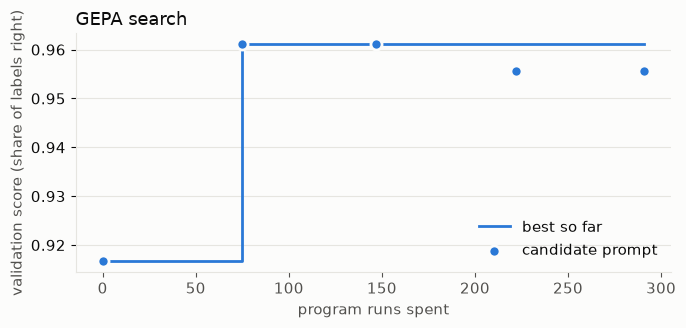

In [9]:
x, y = np.array(gs["discovery_eval_counts"]), np.array(gs["val_scores"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.step(x, np.maximum.accumulate(y), where="post", color=BLUE, lw=2, label="best so far")
ax.scatter(x, y, s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, label="candidate prompt")
ax.set_xlabel("program runs spent"); ax.set_ylabel("validation score (share of labels right)")
ax.set_title("GEPA search", loc="left", color=INK)
ax.grid(axis="y", color=GRID, lw=0.8); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("results/targets_gepa_curve.png", dpi=200); plt.show()

### Base prompt vs GEPA-improved prompt

Left: the starting prompt, which is Climate Policy Radar's own annotation guideline (the definition their experts
labelled with). Right: the prompt after GEPA. Everything on the right beyond the guideline was written by the
teacher model from the student's mistakes.

In [10]:
import html
from IPython.display import HTML, display
before = targets.ClassifyTargets.__doc__
after = list(gs["instructions_tuned"].values())[0]
with open("results/targets_prompts_before_after.md", "w") as f:
    f.write(f"## Base prompt (Climate Policy Radar's annotation guideline)\n\n{before}\n\n## After GEPA\n\n{after}\n")
cell = lambda t: f'<pre style="white-space:pre-wrap;font-size:12px;margin:0">{html.escape(t)}</pre>'
display(HTML('<table style="width:100%;table-layout:fixed"><tr><th style="text-align:left">Base prompt '
             f'({len(before.split())} words)</th><th style="text-align:left">After GEPA ({len(after.split())} words)</th></tr>'
             f'<tr><td style="vertical-align:top">{cell(before)}</td><td style="vertical-align:top">{cell(after)}</td></tr></table>'))

Base prompt (103 words),After GEPA (386 words)
"Identify the climate targets in a passage from a national law, policy or UNFCCC submission. A target is an aim to achieve a specific outcome, that is quantifiable and is given a deadline. Target types: - net_zero: a commitment to balance GHG emissions with removal, effectively reducing the net emissions to zero. - reduction: a target referring to a reduction in greenhouse gas emissions, either economy-wide or for a sector. - other: a target that does not fit into reduction or net zero but satisfies the definition of a target, e.g. renewable energy targets. A passage can contain several target types, or none.","Identify the climate targets in a passage from a national law, policy or UNFCCC submission (passages are often noisy text fragments, e.g. extracted from PDFs, with table remnants, page numbers, or partial sentences). Output: brief reasoning, then three boolean flags: net_zero, reduction, other. A passage can have several true flags, or none. Definition: A target is an aim to achieve a specific outcome that is BOTH quantifiable AND has a deadline (a target year or date). Expert annotators apply this strictly. If either quantification or a deadline is missing, it does not count. Target types: - net_zero: an explicit commitment to balance GHG emissions with removals / reach net zero (or carbon neutrality, climate neutrality) by a date. - reduction: a quantified target to reduce greenhouse gas EMISSIONS (economy-wide or sector-specific, e.g. X% below baseline/BAU by year, or 'halve emissions by 2030') with a deadline. Reductions in energy consumption, trips, waste, etc. are NOT GHG emission reduction targets. Vague aims such as 'decarbonization of the sector' without a quantified figure do not count. Be conservative: if the emissions-reduction statement is vague, loosely worded, ambiguous in scope, or its quantity/deadline cannot be clearly tied to it in a fragmentary passage, mark reduction false. - other: a quantifiable, dated target that is not net zero or GHG reduction, e.g. renewable energy share (20% by 2020, 30% by 2030), EV share of fleet, energy efficiency/consumption reduction, forest cover, nearly-zero-energy building requirements with a date, etc. What is NOT a target: project/process descriptions, activities, measures, policies, studies, institutional development, financing mechanisms, or aspirations without a number and a date. Return all flags false for such passages. Strategy: 1) Scan for explicit net-zero/neutrality commitments with a date. 2) Scan for quantified GHG emission reductions with a date; check that the thing being reduced is really GHG emissions (not energy use or other metrics) and that it is stated clearly with a number. 3) Scan for other quantified, dated goals. 4) For each candidate, verify both quantity and deadline; discard otherwise. Set flags independently. Do not mark reduction merely because the passage mentions 'decarbonization', 'halve emissions' loosely, or energy savings; in the worked example (Andorra-style mobility/building passage with EV shares of 20%/30% by 2030, 50%/70% by 2050, 15% energy consumption reduction, 'Halve emissions' and 'Decarbonization' of transport), experts labeled net_zero=no, reduction=no, other=yes."


## 5. Results on 300 passages from countries never seen in tuning

In [11]:
runs["GEPA-tuned Haiku (Sonnet as teacher)"] = targets.run(tuned, test, haiku, threads=THREADS)
labels_used = {"Naive prompt, Haiku": 0, "Expert definition, Haiku (GEPA's seed)": 0,
               "Expert definition, Sonnet (bigger model)": 0, "GEPA-tuned Haiku (Sonnet as teacher)": len(seen) + len(val)}
rows = []
for n, d in runs.items():
    s = targets.summary(d, n)
    s.update({"labelled_passages_used": labels_used[n], "exact_south_asia": round(d[d.region == "South Asia"].exact.mean(), 3),
              "exact_india": f"{int(d[d.geography == 'IND'].exact.sum())}/{int((d.geography == 'IND').sum())}"})
    rows.append(s)
best_ml = ml.sort_values("exact_match", ascending=False).groupby("train_passages").head(1)
bench = pd.concat([best_ml.rename(columns={"train_passages": "labelled_passages_used"}), pd.DataFrame(rows)],
                  ignore_index=True)
cols = ["setup", "labelled_passages_used", "exact_match", "F1_net_zero", "F1_reduction", "F1_other",
        "false_alarm_rate", "exact_south_asia", "exact_india"]
bench = bench[cols]
bench.to_csv("results/targets_benchmark.csv", index=False)
bench

  0%|          | 0/300 [00:00<?, ?it/s]

Average Metric: 1.00 / 1 (100.0%):   0%|          | 0/300 [00:00<?, ?it/s]

Average Metric: 2.00 / 2 (100.0%):   0%|          | 1/300 [00:00<00:02, 111.72it/s]

Average Metric: 3.00 / 3 (100.0%):   1%|          | 2/300 [00:00<00:02, 130.82it/s]

Average Metric: 4.00 / 4 (100.0%):   1%|          | 3/300 [00:00<00:01, 164.10it/s]

Average Metric: 5.00 / 5 (100.0%):   1%|▏         | 4/300 [00:00<00:01, 210.96it/s]

... (301 outputs left out)

Average Metric: 291.33 / 300 (97.1%): 100%|█████████▉| 299/300 [00:01<00:00, 129.75it/s]

Average Metric: 291.33 / 300 (97.1%): 100%|██████████| 300/300 [00:01<00:00, 289.89it/s]

2026/11/26 17:02:04 INFO dspy.evaluate.evaluate: Average Metric: 291.3333333333333 / 300 (97.1%)


,setup,labelled_passages_used,exact_match,F1_net_zero,F1_reduction,F1_other,false_alarm_rate,exact_south_asia,exact_india
0,"Linear SVM (all 1,839 non-test)",1839,0.753,0.610,0.762,0.589,0.115,0.742,25/32
1,Logistic regression (same 360 as GEPA),360,0.743,0.238,0.677,0.571,0.062,0.784,26/32
2,"Naive prompt, Haiku",0,0.503,0.733,0.468,0.544,0.500,0.660,24/32
3,"Expert definition, Haiku (GEPA's seed)",0,0.847,0.911,0.762,0.835,0.161,0.907,30/32
4,"Expert definition, Sonnet (bigger model)",0,0.847,0.909,0.825,0.806,0.172,0.887,29/32
5,GEPA-tuned Haiku (Sonnet as teacher),99,0.917,0.932,0.882,0.894,0.062,0.948,32/32


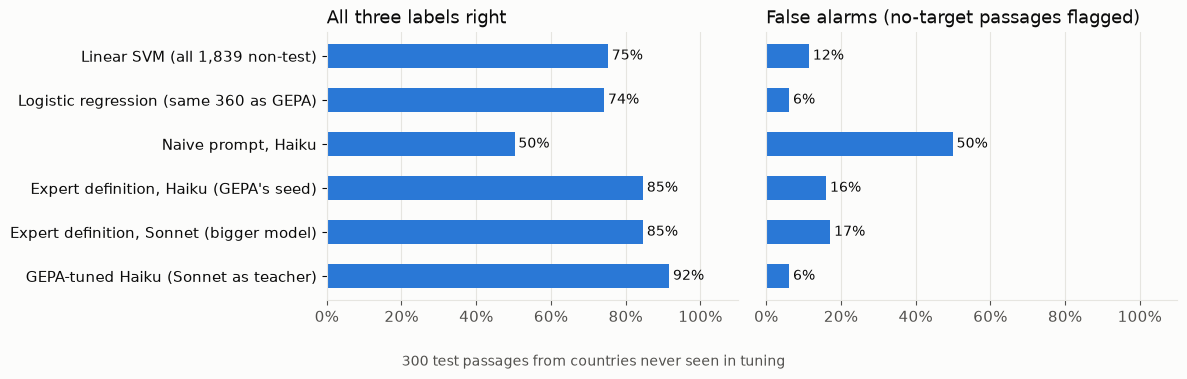

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
b = bench.iloc[::-1]
for ax, col, title in [(axes[0], "exact_match", "All three labels right"),
                       (axes[1], "false_alarm_rate", "False alarms (no-target passages flagged)")]:
    ax.barh(b.setup, b[col], color=BLUE, height=0.55)
    for yv, v in enumerate(b[col]):
        ax.text(v + 0.01, yv, f"{v:.0%}", va="center", color=INK, fontsize=10)
    ax.set_xlim(0, 1.1); ax.set_title(title, loc="left", color=INK)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[1].tick_params(axis="y", length=0)
fig.supxlabel("300 test passages from countries never seen in tuning", color=INK2, fontsize=10)
plt.tight_layout(); plt.savefig("results/targets_benchmark_chart.png", dpi=200); plt.show()

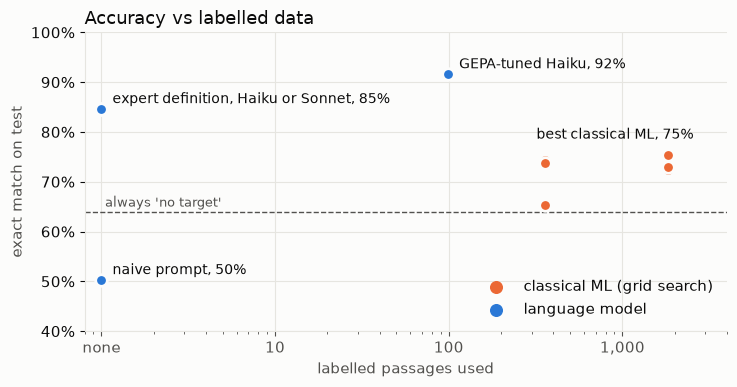

In [13]:
# Labelled data needed vs accuracy (log scale; prompt-only setups use no labels and sit at "none")
fig, ax = plt.subplots(figsize=(7.5, 4))
for _, r in ml.iterrows():
    ax.scatter(r.train_passages, r.exact_match, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3)
for n, d in runs.items():
    ax.scatter(max(labels_used[n], 1), d.exact.mean(), s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
g = runs["GEPA-tuned Haiku (Sonnet as teacher)"].exact.mean()
ax.annotate(f"GEPA-tuned Haiku, {g:.0%}", (labels_used["GEPA-tuned Haiku (Sonnet as teacher)"], g),
            xytext=(8, 4), textcoords="offset points", color=INK, fontsize=10)
top = ml.sort_values("exact_match").iloc[-1]
ax.annotate(f"best classical ML, {top.exact_match:.0%}", (top.train_passages, top.exact_match),
            xytext=(-95, 12), textcoords="offset points", color=INK, fontsize=10)
e = runs["Expert definition, Haiku (GEPA's seed)"].exact.mean()
ax.annotate(f"expert definition, Haiku or Sonnet, {e:.0%}", (1, e), xytext=(8, 4), textcoords="offset points",
            color=INK, fontsize=10)
nv = runs["Naive prompt, Haiku"].exact.mean()
ax.annotate(f"naive prompt, {nv:.0%}", (1, nv), xytext=(8, 4), textcoords="offset points", color=INK, fontsize=10)
ax.axhline(always_none, color=INK2, lw=1, ls="--"); ax.text(1.05, always_none + 0.01, "always 'no target'", color=INK2, fontsize=9)
ax.set_xscale("log"); ax.set_xlim(0.8, 4000); ax.set_ylim(0.4, 1.0)
ax.set_xticks([1, 10, 100, 1000]); ax.set_xticklabels(["none", "10", "100", "1,000"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("labelled passages used"); ax.set_ylabel("exact match on test")
ax.scatter([], [], color=ORANGE, s=70, label="classical ML (grid search)"); ax.scatter([], [], color=BLUE, s=70, label="language model")
ax.legend(frameon=False, loc="lower right"); ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("Accuracy vs labelled data", loc="left", color=INK)
plt.tight_layout(); plt.savefig("results/targets_sample_efficiency.png", dpi=200); plt.show()

In [14]:
# Is GEPA's gain over its own seed real? Paired test on the same 300 passages (exact McNemar test)
s, t = runs["Expert definition, Haiku (GEPA's seed)"], runs["GEPA-tuned Haiku (Sonnet as teacher)"]
fixed, broke = int((~s.exact & t.exact).sum()), int((s.exact & ~t.exact).sum())
n, k = fixed + broke, min(fixed, broke)
p = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)
print(f"GEPA fixed {fixed} passages and broke {broke}; exact McNemar p = {p:.4f}")

GEPA fixed 27 passages and broke 6; exact McNemar p = 0.0003


In [15]:
# Passages GEPA fixed: what the seed said, what the experts said, and the tuned model's reasoning
lab = lambda r, p: ", ".join(k for k in targets.LABELS if r[f"{p}_{k}"]) or "none"
fx = s.index[~s.exact & t.exact]
pd.DataFrame([{"country": s.at[i, "geography"], "passage": s.at[i, "passage"][:220],
               "experts": lab(s.loc[i], "gold"), "seed said": lab(s.loc[i], "pred"),
               "tuned reasoning": str(t.at[i, "reasoning"])[:220]} for i in fx[:8]])

,country,passage,experts,seed said,tuned reasoning
0,BTN,Bhutan has also consistently taken measures to implement the 1st NDC and elaborate on actions and prepare strategies in preparation for ...,none,net_zero,"1. Scan for an explicit net-zero/carbon-neutrality commitment with a date. The passage says Bhutan's ""commitment to remain carbon neutra..."
1,IND,The State Regulatory Commission will devise a specific trajectory so that 24 hours supply of adequate and uninterrupted power can be ens...,none,other,Scan for net-zero or carbon-neutrality commitments with a date: none present. Scan for quantified GHG emission reduction targets with a ...
2,BGD,Bangladesh has taken up a number of initiatives to enhance the best utilization of renewable energy. One such initiative is the preparat...,none,other,Scan the passage for three target types. Net zero: no explicit net-zero or carbon-neutrality commitment with a date. Reduction: the pass...
3,MDV,The targets are: Establish an integrated public passenger transport service by 2010. Halve road transport deaths by 2015 compared to 200...,other,"reduction, other",Scan for net-zero commitments: none present. Scan for GHG emission reduction targets: the CO2 fleet target (140 g/km by 2015) is a quant...
4,MDV,"For planning of the sector activities, the following policy documents have been in use. 1. The Energy Action Plan (2009-2013): includes ...",none,"reduction, other","Scan the passage for net-zero/carbon-neutrality commitments with a date, then for quantified GHG emission reduction targets with a deadl..."
5,IND,"decreased by 12.5 per cent, excluding LULUCF and by 16.6 per cent including LULUCF between 1990 and 2018. The report also says that the ...",none,reduction,Scan for net-zero commitments: none. Scan for quantified GHG reduction targets with a deadline: the passage reports historical reduction...
6,CHN,"Other goals and measures: (1) Net-zero power generation put forward in Figure 28 of the preliminary inspection, no longer use coal for d...","net_zero, other","net_zero, reduction, other",Scan for net-zero commitments with a date: the passage says net-zero power generation by 2050 (explicit net-zero target with a date). Sc...
7,VUT,Vanuatu submitted its initial NDC to the UNFCCC on 21st September 2016. The main mitigation contribution under the initial submission wa...,other,"reduction, other",Scan for net-zero commitments: none; the passage does not mention neutrality or balancing emissions with removals. Scan for GHG emission...


In [16]:
# India: the 32 Indian passages, where seed and tuned answers differ
ind = s.geography.eq("IND")
diff = ind & (s.exact != t.exact)
print(f"India: seed {int(s[ind].exact.sum())}/{int(ind.sum())}, tuned {int(t[ind].exact.sum())}/{int(ind.sum())}")
pd.DataFrame([{"passage": s.at[i, "passage"][:240], "experts": lab(s.loc[i], "gold"),
               "seed said": lab(s.loc[i], "pred"), "tuned said": lab(t.loc[i], "pred")} for i in s.index[diff]])

India: seed 30/32, tuned 32/32


,passage,experts,seed said,tuned said
0,The State Regulatory Commission will devise a specific trajectory so that 24 hours supply of adequate and uninterrupted power can be ens...,none,other,none
1,"decreased by 12.5 per cent, excluding LULUCF and by 16.6 per cent including LULUCF between 1990 and 2018. The report also says that the ...",none,reduction,none


## 6. Five-fold cross-validation by country

One held-out set could be lucky. Here the countries (192 geography codes) are split into 5 groups. In each fold every method is
rebuilt from scratch on the other four groups (classical ML re-fitted with its grid search, GEPA re-run from the
same base prompt) and scored on the same 150 held-out passages. Mean and standard deviation are across the 5 folds.
Classical ML uses the model family with the best inner cross-validation score, never chosen on the test fold.

In [17]:
import re
from gepa_targets import targets_cv
for f in range(5):
    targets_cv.run_fold(f, threads=THREADS, verbose=False)   # replays cached calls and saved GEPA runs
cv_sum, cv_per, cv_infos = targets_cv.load_results()
ORDER = ["Classical ML", "Claude Haiku", "Claude Sonnet", "Claude Haiku + GEPA"]
agg = (cv_sum.groupby("setup").agg(exact_mean=("exact_match", "mean"), exact_sd=("exact_match", "std"),
                                   false_alarm_mean=("false_alarm_rate", "mean"), false_alarm_sd=("false_alarm_rate", "std"))
       .reindex(ORDER).round(3))
agg.to_csv("results/targets_cv_summary.csv")
print("per fold, exact match:")
print(cv_sum.pivot(index="fold", columns="setup", values="exact_match")[ORDER].round(3).to_string())
print("\nclassical ML family chosen per fold:", [i["ml"]["family"] for i in cv_infos])
print("training labels available to ML per fold:", [len(f["pool"]) for f in targets_cv.folds()])
print("labelled passages GEPA used per fold:", [i["gepa"]["labelled_passages_used"] for i in cv_infos])
agg

  0%|          | 0/150 [00:00<?, ?it/s]

Average Metric: 0.67 / 1 (66.7%):   0%|          | 0/150 [00:00<?, ?it/s]

Average Metric: 1.67 / 2 (83.3%):   1%|          | 1/150 [00:00<00:01, 75.99it/s]

Average Metric: 2.00 / 3 (66.7%):   1%|▏         | 2/150 [00:00<00:01, 144.64it/s]

Average Metric: 3.00 / 4 (75.0%):   2%|▏         | 3/150 [00:00<00:00, 209.54it/s]

Average Metric: 4.00 / 5 (80.0%):   3%|▎         | 4/150 [00:00<00:00, 213.80it/s]

... (2,374 outputs left out)

Average Metric: 143.67 / 150 (95.8%): 100%|██████████| 150/150 [00:00<00:00, 303.10it/s]

2026/11/26 17:02:14 INFO dspy.evaluate.evaluate: Average Metric: 143.66666666666666 / 150 (95.8%)


per fold, exact match:
setup  Classical ML  Claude Haiku  Claude Sonnet  Claude Haiku + GEPA
fold                                                                 
0             0.807         0.713          0.760                0.793
1             0.813         0.793          0.813                0.900
2             0.793         0.853          0.840                0.853
3             0.773         0.867          0.833                0.893
4             0.780         0.813          0.827                0.880

classical ML family chosen per fold: ['Logistic regression', 'Linear SVM', 'Linear SVM', 'Logistic regression', 'Linear SVM']
training labels available to ML per fold: [1878, 2197, 2197, 2200, 1968]
labelled passages GEPA used per fold: [84, 84, 75, 84, 87]


,exact_mean,exact_sd,false_alarm_mean,false_alarm_sd
setup,,,,
Classical ML,0.793,0.017,0.073,0.024
Claude Haiku,0.808,0.061,0.209,0.089
Claude Sonnet,0.815,0.032,0.209,0.080
Claude Haiku + GEPA,0.864,0.043,0.130,0.068


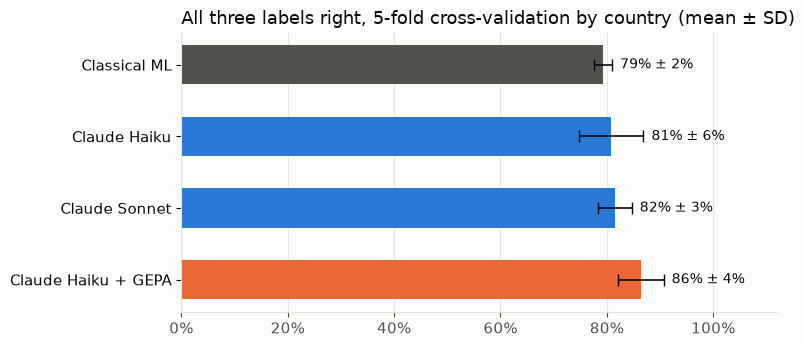

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(ORDER))[::-1]
ax.barh(y, agg.exact_mean, xerr=agg.exact_sd, color=[INK2 if i == 0 else BLUE for i in range(3)] + [ORANGE],
        height=0.55, error_kw=dict(ecolor=INK, capsize=4, lw=1.2))
for yi, m, sd in zip(y, agg.exact_mean, agg.exact_sd):
    ax.text(m + sd + 0.015, yi, f"{m:.0%} ± {sd:.0%}", va="center", color=INK, fontsize=10)
ax.set_yticks(y); ax.set_yticklabels(ORDER); ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("All three labels right, 5-fold cross-validation by country (mean ± SD)", loc="left", color=INK)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("results/targets_cv_chart.png", dpi=200); plt.show()

In [19]:
# Paired test pooled over all held-out passages: GEPA-tuned Haiku vs its own starting prompt
base = pd.concat([cv_per[f]["Claude Haiku"] for f in range(5)], ignore_index=True)
tune = pd.concat([cv_per[f]["Claude Haiku + GEPA"] for f in range(5)], ignore_index=True)
fixed_cv, broke_cv = int((~base.exact & tune.exact).sum()), int((base.exact & ~tune.exact).sum())
n, k = fixed_cv + broke_cv, min(fixed_cv, broke_cv)
p_cv = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)
wins = int(sum(cv_per[f]["Claude Haiku + GEPA"].exact.mean() > cv_per[f]["Claude Haiku"].exact.mean() for f in range(5)))
print(f"{len(base)} held-out passages: GEPA fixed {fixed_cv}, broke {broke_cv}; exact McNemar p = {p_cv:.2g}; "
      f"GEPA beat its base prompt in {wins} of 5 folds")

750 held-out passages: GEPA fixed 55, broke 13; exact McNemar p = 2.7e-07; GEPA beat its base prompt in 4 of 5 folds


In [20]:
# Do the rules GEPA learned in the main run come back when GEPA is re-run in each fold?
RULES = [("Be strict", "Count a goal only if it has both a number and a deadline.",
          ["BOTH quantifiable AND has a deadline"], r"strict"),
         ("Energy savings ≠ emission cuts", "Cutting energy use is an 'other' target, not an emission-reduction target.",
          ["energy consumption", "NOT GHG emission reduction targets"], r"energy consumption"),
         ("Vague does not count", "Aims like 'decarbonise the sector' with no figure are not targets.",
          ["decarbonization of the sector", "do not count"], r"vague"),
         ("Plans are not promises", "Projects, policies, studies and financing are not targets.",
          ["NOT a target:", "measures, policies, studies"], r"not a target"),
         ("Carbon neutral = net zero", "Carbon neutrality and climate neutrality count as net zero.",
          ["net zero (or carbon neutrality, climate neutrality)"], r"carbon neutral")]
rule_rows = []
for name, plain, frags, pat in RULES:
    assert all(fr in after for fr in frags), f"quote not in learned prompt: {name}"   # quotes are verbatim
    rule_rows.append({"rule": name, "plain": plain, "quote": " … ".join(frags),
                      "folds_with_rule": sum(bool(re.search(pat, i["gepa"]["instructions"], re.I)) for i in cv_infos)})
pd.DataFrame(rule_rows)

,rule,plain,quote,folds_with_rule
0,Be strict,Count a goal only if it has both a number and a deadline.,BOTH quantifiable AND has a deadline,2
1,Energy savings ≠ emission cuts,"Cutting energy use is an 'other' target, not an emission-reduction target.",energy consumption … NOT GHG emission reduction targets,0
2,Vague does not count,Aims like 'decarbonise the sector' with no figure are not targets.,decarbonization of the sector … do not count,4
3,Plans are not promises,"Projects, policies, studies and financing are not targets.","NOT a target: … measures, policies, studies",2
4,Carbon neutral = net zero,Carbon neutrality and climate neutrality count as net zero.,"net zero (or carbon neutrality, climate neutrality)",4


## 7. Every passage, classified out of fold

The cross-validation above scored a sample of 150 held-out passages per fold. Here each fold's GEPA-tuned Claude Haiku
labels **every** passage from its own held-out countries, so all 2,610 passages get labels from a model that never saw
their country. These out-of-fold labels, with the model's explanations, feed the browsable page in `docs/`
(served with GitHub Pages).

In [21]:
oof = pd.concat([targets_cv.oof_fold(f, threads=THREADS) for f in range(5)]).sort_values("row").reset_index(drop=True)
assert len(oof) == oof.row.nunique() == len(pd.read_parquet(targets.DATA)), "every passage exactly once"
assert oof.reasoning.notna().all(), "every passage has an explanation"
oof_sum = targets.summary(oof, "Claude Haiku + GEPA, out of fold")
agree = {k: float((oof[f"gold_{k}"] == oof[f"pred_{k}"]).mean()) for k in targets.LABELS}
print(f"{len(oof):,} passages ({N_COUNTRIES} countries and the EU), each labelled by the fold model that never saw it")
print(f"all three labels match the experts: {oof_sum['exact_match']:.1%}")
print("agreement on each label:", {k: f"{v:.1%}" for k, v in agree.items()})
print(f"no-target passages wrongly flagged as targets: {oof_sum['false_alarm_rate']:.1%}")
pd.DataFrame([{"fold": f, "passages": int((oof.fold == f).sum()), "exact_match": round(oof[oof.fold == f].exact.mean(), 3)}
              for f in range(5)])

  0%|          | 0/732 [00:00<?, ?it/s]

Average Metric: 1.00 / 1 (100.0%):   0%|          | 0/732 [00:00<?, ?it/s]

Average Metric: 2.00 / 2 (100.0%):   0%|          | 1/732 [00:00<00:04, 180.96it/s]

Average Metric: 3.00 / 3 (100.0%):   0%|          | 2/732 [00:00<00:06, 119.10it/s]

Average Metric: 4.00 / 4 (100.0%):   0%|          | 3/732 [00:00<00:04, 148.59it/s]

Average Metric: 4.67 / 5 (93.3%):   1%|          | 4/732 [00:00<00:04, 166.46it/s] 

... (2,672 outputs left out)

Average Metric: 605.67 / 642 (94.3%): 100%|██████████| 642/642 [00:02<00:00, 275.31it/s]

2026/11/26 17:02:23 INFO dspy.evaluate.evaluate: Average Metric: 605.6666666666666 / 642 (94.3%)



2,610 passages (189 countries and the EU), each labelled by the fold model that never saw it
all three labels match the experts: 85.2%
agreement on each label: {'net_zero': '97.8%', 'reduction': '93.9%', 'other': '91.9%'}
no-target passages wrongly flagged as targets: 14.2%


,fold,passages,exact_match
0,0,732,0.799
1,1,413,0.901
2,2,413,0.860
3,3,410,0.888
4,4,642,0.852


In [22]:
# Data for the browsable page (docs/index.html): one record per passage
import os, html as _html, pycountry
SPECIAL = {"EUR": ("European Union", "EU"), "UAE": ("United Arab Emirates", "AE"), "XAB": ("International", None)}
def country(code):
    if code in SPECIAL:
        return SPECIAL[code]
    c = pycountry.countries.get(alpha_3=code)
    return getattr(c, "common_name", c.name), c.alpha_2
raw = pd.read_parquet(targets.DATA)
K = list(targets.LABELS)
recs = []
for r in oof.itertuples():
    name, a2 = country(r.geography)
    recs.append({"id": int(r.row), "c": name, "cc": a2, "r": r.region, "f": int(r.fold),
                 "tr": str(raw.at[r.row, "translated"]) == "True", "p": _html.unescape(r.passage),
                 "e": [int(getattr(r, f"gold_{k}")) for k in K], "m": [int(getattr(r, f"pred_{k}")) for k in K],
                 "x": _html.unescape(str(r.reasoning))})
meta = {"n": len(recs), "countries": N_COUNTRIES, "geography_codes": int(oof.geography.nunique()), "exact": round(float(oof_sum["exact_match"]), 4),
        "label_agree": {k: round(v, 4) for k, v in agree.items()}, "label_agree_min": round(min(agree.values()), 4),
        "false_alarm": float(oof_sum["false_alarm_rate"]), "folds": 5}
os.makedirs("docs", exist_ok=True)
# Written as a script (window.PASSAGES = ...) rather than .json so the page also works when opened straight from disk
with open("docs/passages.js", "w") as fh:
    fh.write("window.PASSAGES = " + json.dumps({"meta": meta, "passages": recs}, ensure_ascii=False, separators=(",", ":")) + ";\n")
print(f"docs/passages.js: {len(recs):,} passages, {os.path.getsize('docs/passages.js') / 1e6:.1f} MB")
meta

docs/passages.js: 2,610 passages, 4.4 MB

{'n': 2610,
 'countries': 189,
 'geography_codes': 192,
 'exact': 0.852,
 'label_agree': {'net_zero': 0.9778, 'reduction': 0.9387, 'other': 0.9192},
 'label_agree_min': 0.9192,
 'false_alarm': 0.142,
 'folds': 5}

## 8. Summary

In [23]:
# Summary in words, generated from the cross-validation results above
pct = lambda m, s: f"{m:.0%} ± {s:.0%}"
a = agg
print(f"5-fold cross-validation by country ({int(cv_sum.passages.sum() / len(ORDER))} held-out passages), all 3 answers right:")
for name in ORDER:
    print(f"  {name:22s} {pct(a.loc[name, 'exact_mean'], a.loc[name, 'exact_sd'])}   (wrongly flagged as targets: {a.loc[name, 'false_alarm_mean']:.0%})")
print(f"GEPA beat its zero-shot starting prompt in {wins} of 5 folds (paired exact McNemar p = {p_cv:.2g}).")

5-fold cross-validation by country (750 held-out passages), all 3 answers right:
  Classical ML           79% ± 2%   (wrongly flagged as targets: 7%)
  Claude Haiku           81% ± 6%   (wrongly flagged as targets: 21%)
  Claude Sonnet          82% ± 3%   (wrongly flagged as targets: 21%)
  Claude Haiku + GEPA    86% ± 4%   (wrongly flagged as targets: 13%)
GEPA beat its zero-shot starting prompt in 4 of 5 folds (paired exact McNemar p = 2.7e-07).


In [24]:
print("Claude calls made by this notebook run (cache hits are free and not counted):", usage()["by_model"])

Claude calls made by this notebook run (cache hits are free and not counted): {}
